# Required Installations

Run the 2 cells below to install the necessary packages

In [59]:
!pip install gymnasium

In [60]:
!pip install gym-toytext

# Imports

Run the cell below to import the required Python packages

In [61]:
import gymnasium as gym
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt

# Actions

Create an actions list which contains the numbers that refer to each of the actions listed below:

0: Move Left

1: Move Down

2: Move Right

3: Move Up

In [62]:
# Creat actions list here
actions_list = [0,1,2,3]

In [63]:
# Print actions list to check if it is correct

print(actions_list)

[0, 1, 2, 3]


# States

The states represent each of the squares in the frozen lake below. In the next cell create a states list which contains the numbers 0 - 15 to represent each of the 15 possible positions. The function range(start_number, end_number +1) could be used to create this list.

![image.png](attachment:image.png)



In [64]:
# Creat the states list in this cell
states_list = list(range(16))

In [65]:
# print the list of states here to make sure that it looks correct

print(states_list)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


# Empty Q Table

In the following cells we will build an empty Q table. The row labels will be the states, and the column names will be the actions. Every value in the table should initially be 0. A table full of zeros can be created using the numpy function np.zeros(list of row names, list of column names).

In [66]:
# Create the Q table in this cell
import numpy as np
q_table = np.zeros((len(states_list), len(actions_list)))

In [67]:
# This cell will disply the Q table in a more readable format than the numpy array - do not change this cell

q_table_pd = pd.DataFrame(q_table, index=states_list, columns=actions_list)

# Setup

The cell below contains code which openai gym uses to create the frozen maze environment. It also contains the hyper-parameters for tuning the Q Learning algorithm which you can change to improve performance of the algorithm.

There is also code to reset the Q table to all zeros which we will need to do when trying new hyper-parameters. Also some empty lists are made here for recording data during the training process.

### The cell below must be run before the Training Loop section is run every single time



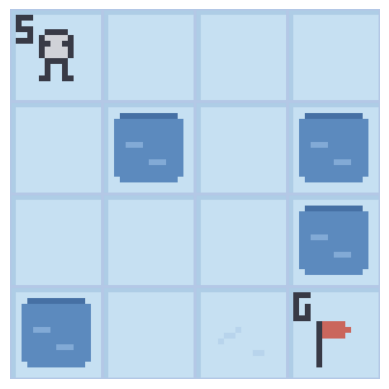

In [68]:
# Builds the game envronment - only change which env is commented out to display or hide the maze graphics
env = gym.make("FrozenLake-v1", is_slippery = True, render_mode = "rgb_array")

state, info = env.reset()

image = env.render()
plt.imshow(image)
plt.axis("off")
plt.show()

terminated = False
truncated = False

# Hyper-parameters - feel free to change these
episodes = 2000
alpha = 0.1 # Learning rate
gamma = 0.99 # Discount rate
epsilon = 1
epsilon_decay = 0.001

# Resets the Q table to zeros - do not change
q_table = np.zeros([len(states_list), len(actions_list)])

# Empty list for collecting the return after each episode
all_returns = []
all_epsilons = []



# Training Loop

This section contains the main bulk of code for training the Q Learning algorithm.

At the beginning of each episode the environment will be reset to teh initial state. Epsilon will also be set according to the hyper-parameters.

The epsilon-greedy algorithm will be implemented below to be used for selecting an action at each time step during the episode. Use the pseudo-code in the slides to assist with writing this. The function max(varaible 1, variable 2) can be used to fix epsilon to zero if the calculated value drops below 0.

The function np.random.uniform(low=0, high=1, size=none) can be used to generate a random number between 0 and 1. The function np.argmax(q_table[state]) can be used to select the action with the highest Q value in the current state.

After selecting an action the openai gym function env.step(action) is used to take the action inside the environment, get the new state, and calculate the reward.


The Q table will be updated using the equation from the slides. The function np.max(q_table[next_state]) can be used to find the highest q value relating to the best action in the new state.

At the end of every episode the environment is reset, ready for the next episode.


In [69]:
for episode in range(episodes):

    # Reset the environment
    state, info = env.reset()
    terminated = False
    truncated = False
    episode_return = 0


    # Set epsilon for the episode
    if episode==0:
      epsilon=1
    else:
      epsilon=max(epsilon-epsilon_decay,0)

    # Save epsilon value for plotting later
    all_epsilons.append(epsilon)


    # The main loop to take steps in the episode
    while not terminated and not truncated:

        # Choose an action using epsilon greedy algorithm
        random_number=np.random.uniform(low=0, high=1, size= None)
        if random_number < epsilon:
         action=random.choice(actions_list)
        else:
         action=np.argmax(q_table[state])


        # Take the action and get the new state, the reward and check if the episode should end
        new_state, reward, terminated, truncated, info = env.step(action)


        # Add the reward to the return
        episode_return += reward


        # Update Q Table
        current_q_value=q_table[state, action]
        new_q_value=current_q_value + alpha*(reward+gamma*np.max(q_table[new_state])-current_q_value)
        q_table[state,action]=new_q_value

        # Update current state to new state
        state=new_state


    print('Episode: ', episode,'Return: ', episode_return, 'Epsilon: ', epsilon, "state: ", state)

    # Collect return from episode
    all_returns.append(episode_return)


env.close()

Episode:  0 Return:  0 Epsilon:  1 state:  7
Episode:  1 Return:  0 Epsilon:  0.999 state:  12
Episode:  2 Return:  0 Epsilon:  0.998 state:  5
Episode:  3 Return:  0 Epsilon:  0.997 state:  5
Episode:  4 Return:  0 Epsilon:  0.996 state:  5
Episode:  5 Return:  0 Epsilon:  0.995 state:  5
Episode:  6 Return:  0 Epsilon:  0.994 state:  5
Episode:  7 Return:  1 Epsilon:  0.993 state:  15
Episode:  8 Return:  0 Epsilon:  0.992 state:  5
Episode:  9 Return:  0 Epsilon:  0.991 state:  7
Episode:  10 Return:  0 Epsilon:  0.99 state:  5
Episode:  11 Return:  0 Epsilon:  0.989 state:  7
Episode:  12 Return:  0 Epsilon:  0.988 state:  11
Episode:  13 Return:  0 Epsilon:  0.987 state:  12
Episode:  14 Return:  0 Epsilon:  0.986 state:  5
Episode:  15 Return:  0 Epsilon:  0.985 state:  5
Episode:  16 Return:  0 Epsilon:  0.984 state:  5
Episode:  17 Return:  0 Epsilon:  0.983 state:  5
Episode:  18 Return:  0 Epsilon:  0.982 state:  5
Episode:  19 Return:  0 Epsilon:  0.981 state:  5
Episode:  2

In [70]:
# Print the updated Q table

print('Q table after training:')
q_table_pd = pd.DataFrame(q_table, index=states_list, columns=actions_list)
print(q_table_pd)

Q table after training:
           0         1         2         3
0   0.539072  0.322144  0.285126  0.297414
1   0.134954  0.135049  0.077739  0.414724
2   0.324149  0.114230  0.046386  0.098770
3   0.027969  0.017827  0.006615  0.104203
4   0.559006  0.264995  0.194392  0.211280
5   0.000000  0.000000  0.000000  0.000000
6   0.287091  0.067056  0.065059  0.024754
7   0.000000  0.000000  0.000000  0.000000
8   0.244254  0.190666  0.260511  0.610150
9   0.210273  0.629766  0.225286  0.139311
10  0.645102  0.261038  0.223791  0.119179
11  0.000000  0.000000  0.000000  0.000000
12  0.000000  0.000000  0.000000  0.000000
13  0.267551  0.308844  0.789612  0.334594
14  0.354317  0.928058  0.484738  0.561874
15  0.000000  0.000000  0.000000  0.000000


# Plot results

The cells below can be used to plot the return and epsilon for each epsiode. These can be used for checking the performance of the simulation.

Do not change these cells

In [71]:
# Convert the return and epsilon data to a pandas dataframe for graphing

returns_df = pd.DataFrame(all_returns)
epsilon_df = pd.DataFrame(all_epsilons)

Text(0.5, 1.03, 'Return from each episode')

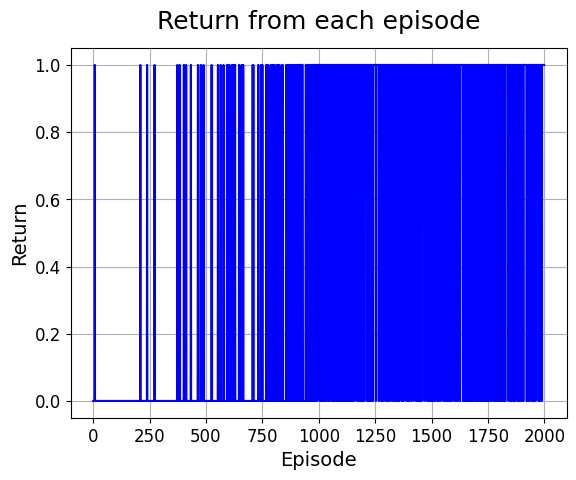

In [72]:
# Plot the return from each episode
fig, ax = plt.subplots()
ax.plot(range(episodes), returns_df[0], 'b', label = 'Return & Epsilon')

plt.grid()
plt.xlabel('Episode', fontsize=14)
plt.ylabel('Return', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
plt.title('Return from each episode', fontsize = 18, x = 0.5, y = 1.03)

Text(0.5, 1.03, 'Epsilon Decay')

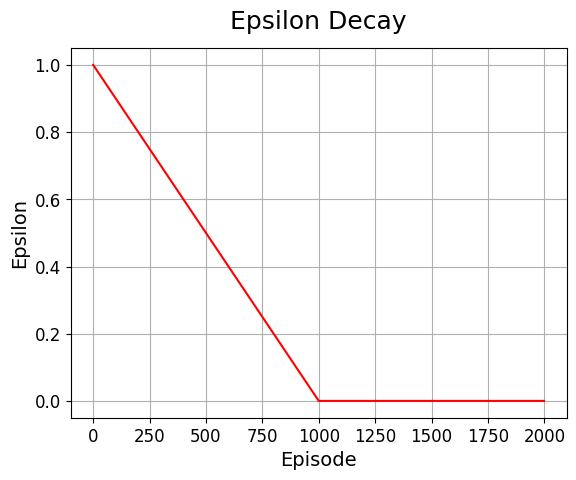

In [73]:
# Plot Epsilon
fig, ax = plt.subplots()
ax.plot(range(episodes), epsilon_df[0], '-r', label = 'Outdoor Temp')

plt.grid()
plt.xlabel('Episode', fontsize=14)
plt.ylabel('Epsilon', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=12)
plt.title('Epsilon Decay', fontsize = 18, x = 0.5, y = 1.03)

# Evaluation

The next cell will run a series of tests which will test the performance of your Q Learning algorithm. You will be given a score out of 100.

In [74]:
episodes = 1000
nb_success = 0


env = gym.make("FrozenLake-v1", is_slippery = True)

# Evaluation
for episode in range(episodes):

    state, info = env.reset()
    truncated = False
    terminated = False

    while not terminated and not truncated:
        # Choose the action with the highest value in the current state
        action = np.argmax(q_table[state])
        value = np.max(q_table[state])


        new_state, reward, terminated, truncated, info, = env.step(action)


        # Update our current state
        state = new_state

        # When we get a reward, it means we solved the game
        nb_success += int(float(reward) > 0)


# Let's check our success rate!
print (f"Success rate = {nb_success/episodes*100}%")

env.close()

Success rate = 75.3%


IF you want to see the real-time agency then :

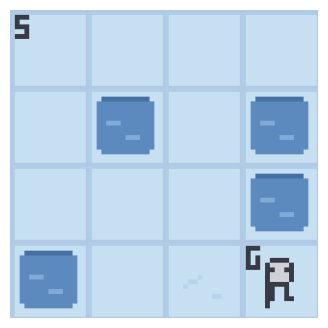

Success rate = 73.80%


In [75]:

import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

episodes = 1000
nb_success = 0

env = gym.make(
    "FrozenLake-v1",
    is_slippery = True,
    render_mode = "rgb_array"
)

# Evaluation
for episode in range(episodes):
    state, info = env.reset()
    terminated = False
    truncated = False

    while not terminated and not truncated:
        # Choose the action with the highest value in the current state
        action = np.argmax(q_table[state])

        new_state, reward, terminated, truncated, info = env.step(action)

        # Update our current state
        state = new_state

        # Display the first episode in Google Colab
        if episode == 0:
            clear_output(wait=True)
            plt.figure(figsize=(4, 4))
            plt.imshow(env.render())
            plt.axis("off")
            display(plt.gcf())
            plt.close()
            time.sleep(0.3)

    # Count success once per episode
    nb_success += int(float(reward) > 0)

# Check success rate
print(f"Success rate = {nb_success / episodes * 100:.2f}%")

env.close()
